###merging

In [267]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [268]:
orders = pd.read_csv("prepared_orders.csv")
reviews = pd.read_csv("clean_order_reviews.csv")
print(orders.shape, reviews.shape)

(98972, 19) (98673, 9)


In [269]:
merged = orders.merge(reviews, on="order_id", how="left", validate="one_to_one")
print(merged.shape)
merged

(98972, 27)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,...,flag_outlier_delivery_duration_days,flag_outlier_delivery_total_duration_days,review_id,review_score,review_creation_date,review_answer_timestamp,flag_answer_before_review,has_comment,days_to_answer,is_low_review
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,...,False,False,a54f0611adc9ed256b57ede6b6eb5114,4.0,2017-10-11 00:00:00,2017-10-12 03:43:48,False,True,1.155417,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,...,False,False,8d5266042046a06655c8db133d120ba5,4.0,2018-08-08,2018-08-08 18:37:50,False,True,0.776273,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,...,False,False,e73b67b67587f7644d5bd1a52deb1b01,5.0,2018-08-18,2018-08-22 19:07:58,False,False,4.797199,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,...,False,False,359d03e676b3c069f62cadba8dd3f6e8,5.0,2017-12-03,2017-12-05 19:21:58,False,True,2.806921,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,...,False,False,e50934924e227544ba8246aeb3770dd4,5.0,2018-02-17,2018-02-18 13:02:51,False,False,1.543646,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98967,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,...,False,False,e262b3f92d1ce917aa412a9406cf61a6,5.0,2017-03-22 00:00:00,2017-03-23 11:02:08,False,False,1.459815,False
98968,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,...,False,False,29bb71b2760d0f876dfa178a76bc4734,4.0,2018-03-01,2018-03-02 17:50:01,False,True,1.743067,False
98969,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,...,False,False,371579771219f6db2d830d50805977bb,5.0,2017-09-22 00:00:00,2017-09-22 23:10:57,False,True,0.965938,False
98970,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,...,False,False,8ab6855b9fe9b812cd03a480a25058a1,2.0,2018-01-26,2018-01-27 09:16:56,False,True,1.386759,True


#handel the difference between the tow datasets

In [270]:
print("Orders without a review:", merged["review_score"].isna().sum())
print("Reviews with no matching order:", (~reviews["order_id"].isin(orders["order_id"])).sum())



Orders without a review: 765
Reviews with no matching order: 466


In [271]:
before = len(reviews)
reviews = reviews[reviews["order_id"].isin(orders["order_id"])].copy()
print("Reviews removed (no matching order):", before - len(reviews))
print("Reviews left:", len(reviews))

print('###################')
print("Orders without a review:", merged["review_score"].isna().sum())
print("Reviews with no matching order:", (~reviews["order_id"].isin(orders["order_id"])).sum())


Reviews removed (no matching order): 466
Reviews left: 98207
###################
Orders without a review: 765
Reviews with no matching order: 0


In [272]:
merged.to_csv("orders_master.csv", index=False, na_rep="N/A")

merged

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,...,flag_outlier_delivery_duration_days,flag_outlier_delivery_total_duration_days,review_id,review_score,review_creation_date,review_answer_timestamp,flag_answer_before_review,has_comment,days_to_answer,is_low_review
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,...,False,False,a54f0611adc9ed256b57ede6b6eb5114,4.0,2017-10-11 00:00:00,2017-10-12 03:43:48,False,True,1.155417,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,...,False,False,8d5266042046a06655c8db133d120ba5,4.0,2018-08-08,2018-08-08 18:37:50,False,True,0.776273,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,...,False,False,e73b67b67587f7644d5bd1a52deb1b01,5.0,2018-08-18,2018-08-22 19:07:58,False,False,4.797199,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,...,False,False,359d03e676b3c069f62cadba8dd3f6e8,5.0,2017-12-03,2017-12-05 19:21:58,False,True,2.806921,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,...,False,False,e50934924e227544ba8246aeb3770dd4,5.0,2018-02-17,2018-02-18 13:02:51,False,False,1.543646,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98967,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,...,False,False,e262b3f92d1ce917aa412a9406cf61a6,5.0,2017-03-22 00:00:00,2017-03-23 11:02:08,False,False,1.459815,False
98968,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,...,False,False,29bb71b2760d0f876dfa178a76bc4734,4.0,2018-03-01,2018-03-02 17:50:01,False,True,1.743067,False
98969,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,...,False,False,371579771219f6db2d830d50805977bb,5.0,2017-09-22 00:00:00,2017-09-22 23:10:57,False,True,0.965938,False
98970,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,...,False,False,8ab6855b9fe9b812cd03a480a25058a1,2.0,2018-01-26,2018-01-27 09:16:56,False,True,1.386759,True


###DATA CLEANING

check keys and duplicates

In [273]:
merged["order_id"] = merged["order_id"].astype("string").str.strip()
print("Duplicate order_id:", merged["order_id"].duplicated().sum())
print("Duplicate full rows:", merged.duplicated().sum())
print("Review score outside 1-5:", (~merged["review_score"].dropna().between(1, 5)).sum())

Duplicate order_id: 0
Duplicate full rows: 0
Review score outside 1-5: 0


NULL handelling

In [274]:
merged.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0
flag_approved_before_purchase,0
flag_carrier_before_approval,0


In [275]:
print(merged.isna().sum().sum())

print("#######################################")

nulls = merged.isna().sum()
nulls = nulls[nulls > 0]
print(pd.DataFrame({"nulls": nulls, "percent": (nulls / len(merged) * 100).round(1)}))

11075
#######################################
                               nulls  percent
order_approved_at                160      0.2
order_delivered_carrier_date    1783      1.8
order_delivered_customer_date   2965      3.0
approval_days                     14      0.0
carrier_days                      16      0.0
delivery_duration_days             9      0.0
delivery_total_duration_days       8      0.0
review_id                        765      0.8
review_score                     765      0.8
review_creation_date             765      0.8
review_answer_timestamp          765      0.8
flag_answer_before_review        765      0.8
has_comment                      765      0.8
days_to_answer                   765      0.8
is_low_review                    765      0.8


In [278]:
date_cols = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
dur_cols = ["approval_days", "carrier_days", "delivery_duration_days", "delivery_total_duration_days"]
rev_cols = ["review_id", "review_score"]

# 1. Missing dates -> order_status value
for c in date_cols:
    merged[c] = merged[c].astype("object")
    merged[c] = merged[c].where(merged[c].notna(), merged["order_status"].astype(str))

# 2. Missing durations -> -1
for c in dur_cols:
    merged[c] = merged[c].fillna(-1)

# 3. Missing review fields -> N/A
for c in rev_cols:
    merged[c] = merged[c].astype("object").fillna("N/A")

for c in ["review_creation_date", "review_answer_timestamp"]:
    merged[c] = merged[c].astype("object").fillna("N/A")

print("Nulls left in review dates:", merged[["review_creation_date", "review_answer_timestamp"]].isna().sum().sum())

print("Nulls left in these columns:", merged[date_cols + dur_cols + rev_cols].isna().sum().sum())

# Removed 'delivery_delay_days' from here because it is engineered later in cell BEE6KMZeVCh4
for c in ["is_low_review", "days_to_answer"]:
    merged[c] = merged[c].astype("object").fillna("N/A")

print("Nulls left in these columns:", merged[["is_low_review", "days_to_answer"]].isna().sum().sum())

Nulls left in review dates: 0
Nulls left in these columns: 0
Nulls left in these columns: 0


In [279]:
if (merged["flag_answer_before_review"].astype(str) == "True").sum() == 0:
    merged = merged.drop(columns=["flag_answer_before_review"])
    print("Column removed")

Column removed


In [280]:
merged.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,0
order_delivered_carrier_date,0
order_delivered_customer_date,0
order_estimated_delivery_date,0
flag_approved_before_purchase,0
flag_carrier_before_approval,0


###Data transformation

convert dates and keep the study period

In [281]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date",
             "review_creation_date", "review_answer_timestamp"]
for c in date_cols:
    merged[c] = pd.to_datetime(merged[c], errors="coerce")

before = len(merged)
merged = merged[merged["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")]
print("Removed outside study period:", before - len(merged))

merged

Removed outside study period: 347


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,...,flag_outlier_carrier_days,flag_outlier_delivery_duration_days,flag_outlier_delivery_total_duration_days,review_id,review_score,review_creation_date,review_answer_timestamp,has_comment,days_to_answer,is_low_review
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,...,False,False,False,a54f0611adc9ed256b57ede6b6eb5114,4.0,2017-10-11,2017-10-12 03:43:48,True,1.155417,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,...,False,False,False,8d5266042046a06655c8db133d120ba5,4.0,NaT,2018-08-08 18:37:50,True,0.776273,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,...,False,False,False,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaT,2018-08-22 19:07:58,False,4.797199,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,...,False,False,False,359d03e676b3c069f62cadba8dd3f6e8,5.0,NaT,2017-12-05 19:21:58,True,2.806921,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,...,False,False,False,e50934924e227544ba8246aeb3770dd4,5.0,NaT,2018-02-18 13:02:51,False,1.543646,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98967,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,...,False,False,False,e262b3f92d1ce917aa412a9406cf61a6,5.0,2017-03-22,2017-03-23 11:02:08,False,1.459815,False
98968,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,...,False,False,False,29bb71b2760d0f876dfa178a76bc4734,4.0,NaT,2018-03-02 17:50:01,True,1.743067,False
98969,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,...,False,False,False,371579771219f6db2d830d50805977bb,5.0,2017-09-22,2017-09-22 23:10:57,True,0.965938,False
98970,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,...,False,False,False,8ab6855b9fe9b812cd03a480a25058a1,2.0,NaT,2018-01-27 09:16:56,True,1.386759,True


set types and create flags

In [282]:
merged["has_review"] = merged["review_score"].notna().astype(int)
merged["has_comment"] = merged["has_comment"].fillna(0).astype(int)

###Feature engineering

In [283]:
merged["estimated_days"] = (merged["order_estimated_delivery_date"]
                            - merged["order_purchase_timestamp"]).dt.total_seconds() / 86400

merged["delivery_delay_days"] = ((merged["order_delivered_customer_date"]
                                  - merged["order_estimated_delivery_date"]).dt.total_seconds() / 86400
                                 ).where(merged["order_status"] == 5)

NULL handelling


In [284]:
merged.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,135
order_delivered_carrier_date,1716
order_delivered_customer_date,2888
order_estimated_delivery_date,0
flag_approved_before_purchase,0
flag_carrier_before_approval,0


Correlation matrix

                              approval_days  carrier_days  \
approval_days                          1.00         -0.03   
carrier_days                          -0.03          1.00   
delivery_duration_days                 0.02          0.03   
delivery_total_duration_days           0.09          0.38   
estimated_days                         0.04          0.18   
review_score                          -0.02         -0.16   
days_to_answer                         0.00          0.00   
has_comment                            0.01          0.03   

                              delivery_duration_days  \
approval_days                                   0.02   
carrier_days                                    0.03   
delivery_duration_days                          1.00   
delivery_total_duration_days                    0.93   
estimated_days                                  0.34   
review_score                                   -0.30   
days_to_answer                                  0.01   
ha

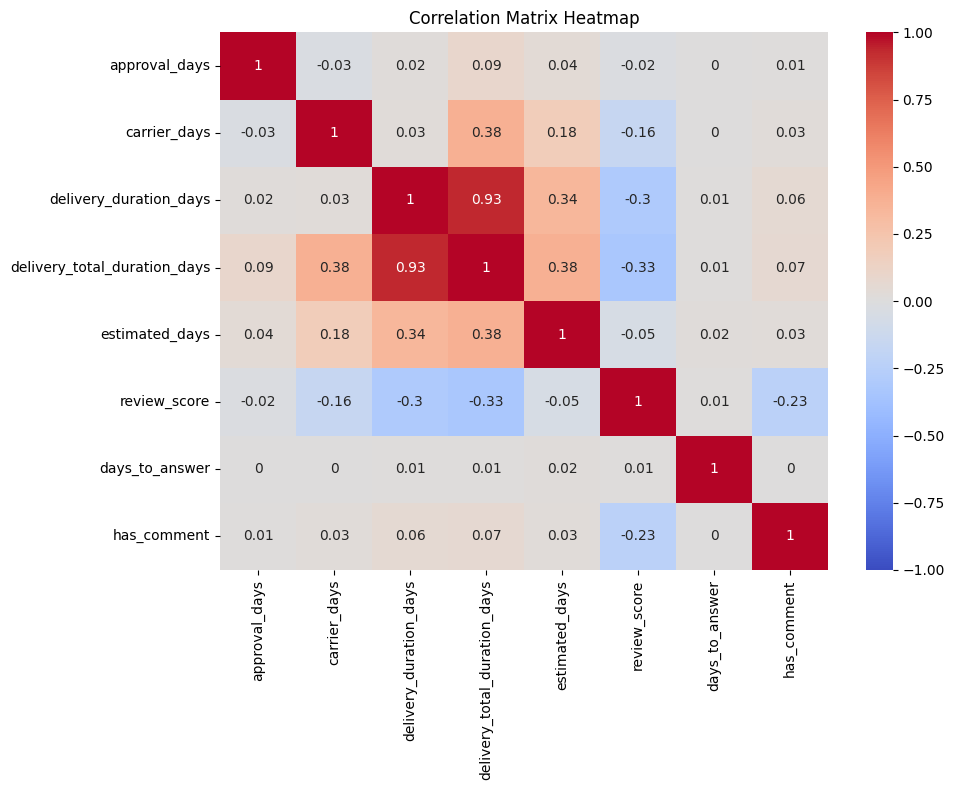

In [285]:
# Correcting 'is_delivered' because order_status is represented by numeric codes (5 means delivered)
merged["is_delivered"] = (merged["order_status"] == 5).astype(int)

corr_cols = ["approval_days", "carrier_days", "delivery_duration_days",
             "delivery_total_duration_days", "estimated_days",
             "review_score", "days_to_answer", "has_comment"]

# Safely convert columns to numeric, coercing strings like 'N/A' to NaN
df_corr = merged.loc[merged["is_delivered"] == 1, corr_cols].copy()
for col in corr_cols:
    df_corr[col] = pd.to_numeric(df_corr[col], errors="coerce")

corr = df_corr.corr().round(2)
print(corr)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2g")
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

PCA

In [286]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_cols = ["approval_days", "carrier_days", "delivery_duration_days",
            "delivery_total_duration_days", "estimated_days"]

X = merged.loc[merged["is_delivered"] == 1, pca_cols].astype(float).dropna()
Xs = StandardScaler().fit_transform(X)

pca_all = PCA().fit(Xs)
print("Explained per component:", np.round(pca_all.explained_variance_ratio_, 3))
print("Cumulative:", np.round(np.cumsum(pca_all.explained_variance_ratio_), 3))

Explained per component: [0.452 0.204 0.191 0.152 0.   ]
Cumulative: [0.452 0.657 0.848 1.    1.   ]


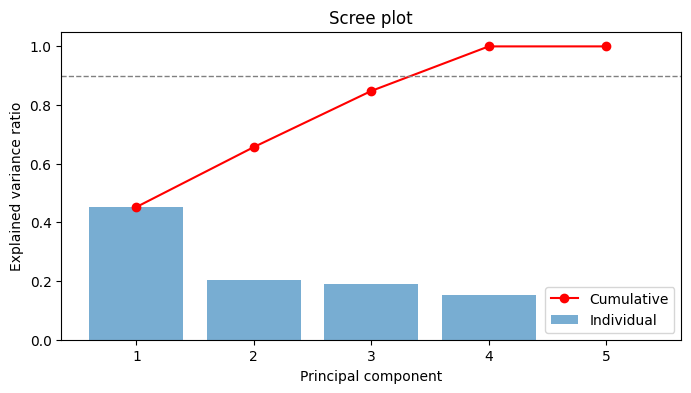

In [287]:
# PCA scree plot
n = len(pca_all.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, n + 1), pca_all.explained_variance_ratio_, alpha=0.6, label='Individual')
ax.plot(range(1, n + 1), np.cumsum(pca_all.explained_variance_ratio_), 'ro-', label='Cumulative')
ax.axhline(0.9, color='gray', ls='--', lw=1)
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('Scree plot')
ax.set_xticks(range(1, n + 1))
ax.legend()
plt.show()

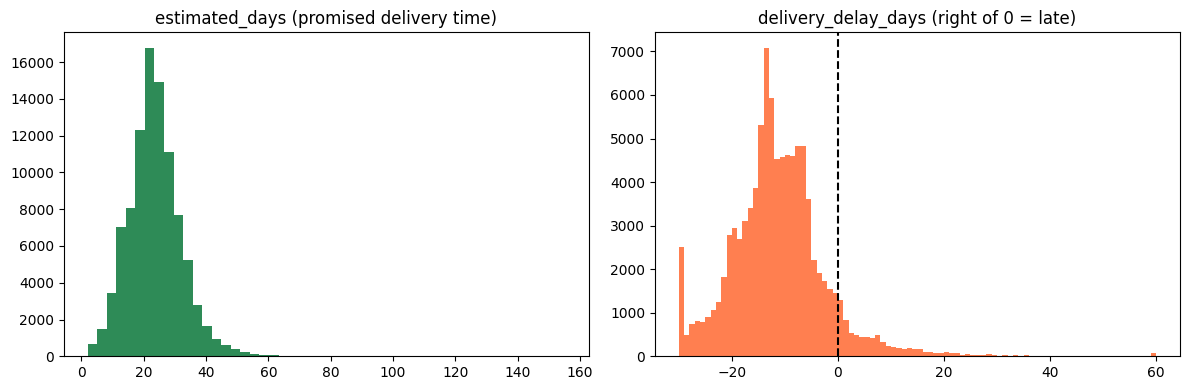

In [288]:
delivered = merged["order_status"] == 5
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(merged.loc[delivered, "estimated_days"].dropna(), bins=50, color="seagreen")
axes[0].set_title("estimated_days (promised delivery time)")

delay = pd.to_numeric(merged.loc[delivered, "delivery_delay_days"], errors="coerce").dropna()
axes[1].hist(delay.clip(-30, 60), bins=90, color="coral")
axes[1].axvline(0, color="black", ls="--")
axes[1].set_title("delivery_delay_days (right of 0 = late)")

plt.tight_layout()
plt.show()

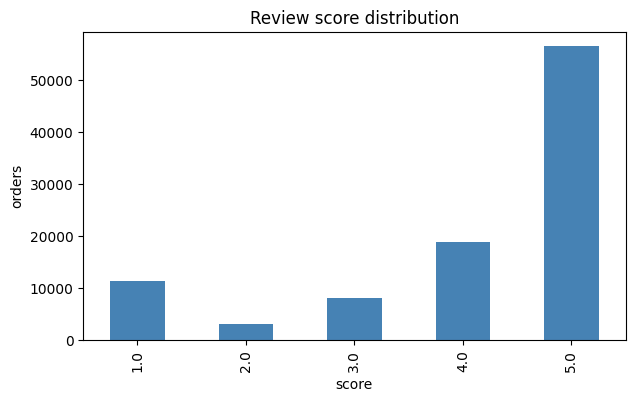

In [289]:
scores = pd.to_numeric(merged["review_score"], errors="coerce").dropna()
scores.value_counts().sort_index().plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.title("Review score distribution")
plt.xlabel("score")
plt.ylabel("orders")
plt.show()

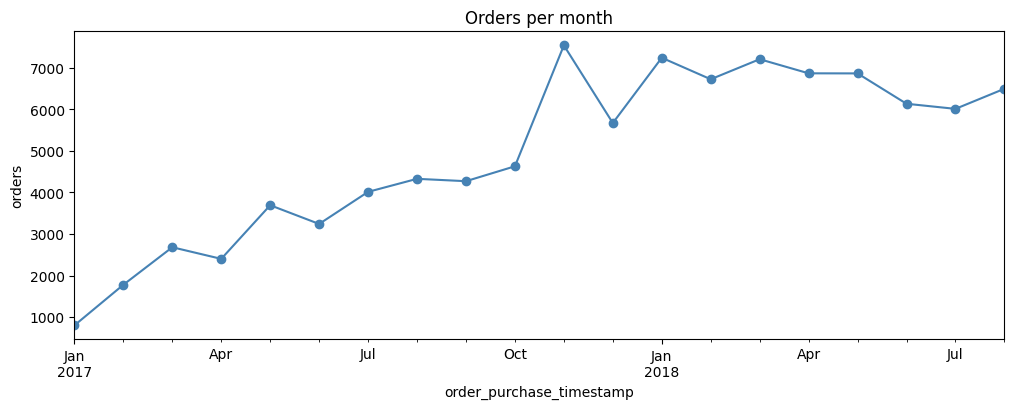

In [290]:
merged.set_index("order_purchase_timestamp").sort_index().resample("MS").size().plot(
    figsize=(12, 4), marker="o", color="steelblue")
plt.title("Orders per month")
plt.ylabel("orders")
plt.show()

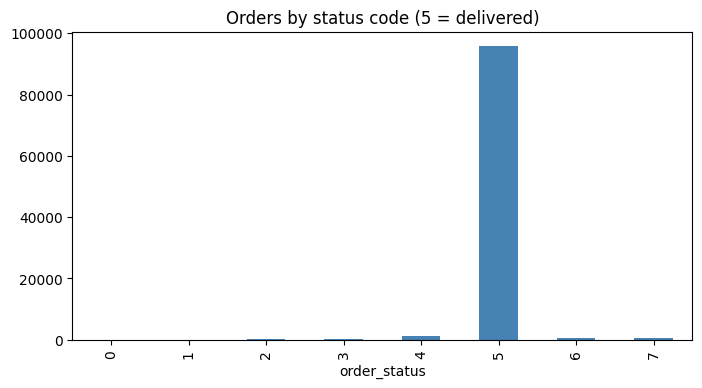

In [291]:
merged["order_status"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Orders by status code (5 = delivered)")
plt.show()

In [292]:
from google.colab import files

# Export the latest 'merged' dataframe to a CSV file
merged.to_csv('orders_master.csv', index=False)

# Trigger the local browser download
files.download('orders_master.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>